# Handwritten Character Recognition: improving the CNN (v2)

CodeAlpha Machine Learning internship, Task 3 (second notebook).

The baseline CNN (see the first notebook) scores about 87% on EMNIST Balanced. Here we add one improvement at a time (BatchNorm and a deeper network, data augmentation, a learning-rate schedule, an ensemble) and record validation and test accuracy after each step, so the effect of every change is visible.

All runs use the same stratified train/validation split (seed 42). Choices are judged on the validation set; the test set is reported alongside and never used to tune anything.

Data: Kaggle dataset *EMNIST (Extended MNIST)* by Chris Crawford. Run on a Kaggle GPU (T4).

## 1. Load the EMNIST Balanced data

Train: (112800, 28, 28) Test: (18800, 28, 28) Classes: 47


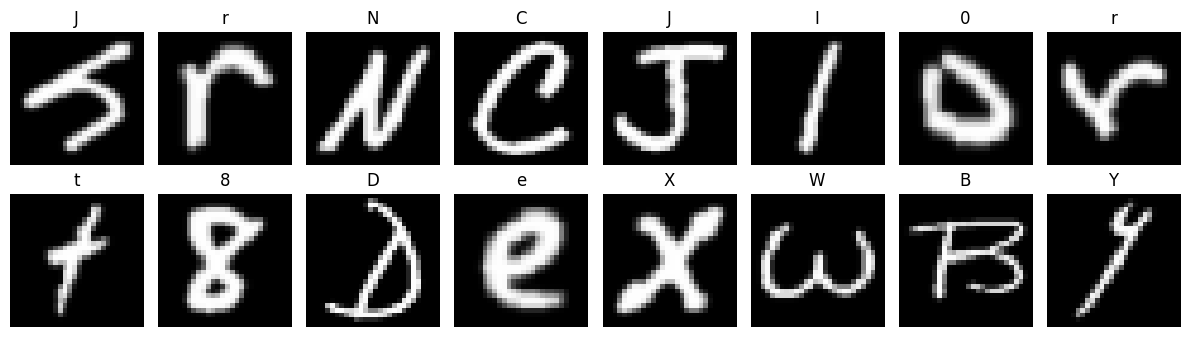

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DIR = "/kaggle/input/datasets/crawford/emnist/"
train = pd.read_csv(DIR + "emnist-balanced-train.csv", header=None)
test = pd.read_csv(DIR + "emnist-balanced-test.csv", header=None)

# label -> character (ASCII code in the mapping file)
mapping = {int(a): chr(int(b)) for a, b in (line.split() for line in open(DIR + "emnist-balanced-mapping.txt"))}

def to_images(df):
    y = df[0].values
    # EMNIST images are stored transposed, so swap the two image axes
    X = df.drop(columns=0).values.reshape(-1, 28, 28).transpose(0, 2, 1).astype("float32") / 255.0
    return X, y

X_train_full, y_train_full = to_images(train)
X_test, y_test = to_images(test)
print("Train:", X_train_full.shape, "Test:", X_test.shape, "Classes:", len(mapping))

fig, axes = plt.subplots(2, 8, figsize=(12, 3.5))
for ax, i in zip(axes.ravel(), np.random.RandomState(0).choice(len(X_train_full), 16, replace=False)):
    ax.imshow(X_train_full[i], cmap="gray"); ax.set_title(mapping[y_train_full[i]]); ax.axis("off")
plt.tight_layout(); plt.show()

## 2. Model builder and experiment runner

In [7]:
import time
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split

print("TensorFlow", tf.__version__, "| GPUs:", tf.config.list_physical_devices("GPU"))
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.1, random_state=42, stratify=y_train_full)
X_train, X_val, X_test_c = X_train[..., None], X_val[..., None], X_test[..., None]

def build(arch, aug, seed):
    keras.utils.set_random_seed(seed)
    m = keras.Sequential([layers.Input(shape=(28, 28, 1))])
    if aug:
        m.add(layers.RandomRotation(0.04, fill_mode="constant"))
        m.add(layers.RandomTranslation(0.08, 0.08, fill_mode="constant"))
        m.add(layers.RandomZoom(0.1, fill_mode="constant"))
    if arch == "base":
        for f in (32, 64):
            m.add(layers.Conv2D(f, 3, activation="relu"))
            m.add(layers.MaxPooling2D())
        m.add(layers.Flatten())
        m.add(layers.Dense(128, activation="relu"))
        m.add(layers.Dropout(0.4))
    else:
        for f in (32, 64):
            for _ in range(2):
                m.add(layers.Conv2D(f, 3, padding="same", use_bias=False))
                m.add(layers.BatchNormalization())
                m.add(layers.Activation("relu"))
            m.add(layers.MaxPooling2D())
            m.add(layers.Dropout(0.25))
        m.add(layers.Flatten())
        m.add(layers.Dense(256, use_bias=False))
        m.add(layers.BatchNormalization())
        m.add(layers.Activation("relu"))
        m.add(layers.Dropout(0.5))
    m.add(layers.Dense(47, activation="softmax"))
    return m

results = {}
def run(name, arch, aug=False, epochs=8, patience=2, schedule=False, seed=42):
    m = build(arch, aug, seed)
    m.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    cbs = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True)]
    if schedule:
        cbs.append(keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-5))
    t = time.time()
    h = m.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=epochs, batch_size=128, callbacks=cbs, verbose=0)
    va = m.evaluate(X_val, y_val, verbose=0)[1]
    te = m.evaluate(X_test_c, y_test, verbose=0)[1]
    results[name] = {"epochs_run": len(h.history["loss"]), "val_acc": round(va, 4), "test_acc": round(te, 4), "params": m.count_params(), "minutes": round((time.time() - t) / 60, 1)}
    print(name, results[name])
    return m

TensorFlow 2.21.0 | GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


## 3. Ablation: add one improvement at a time

In [8]:
models = {}
models["E0"] = run("E0 baseline (v1 recipe)", "base")
models["E1"] = run("E1 + BatchNorm, deeper", "bn")
models["E1b"] = run("E1b control: E1 for 20 epochs", "bn", epochs=20, patience=4)
models["E2"] = run("E2 + augmentation, 20 epochs", "bn", aug=True, epochs=20, patience=4)
models["E3"] = run("E3 + LR schedule, 30 epochs", "bn", aug=True, epochs=30, patience=5, schedule=True)
print(pd.DataFrame(results).T.to_string())

E0 baseline (v1 recipe) {'epochs_run': 8, 'val_acc': 0.8778, 'test_acc': 0.8751, 'params': 229807, 'minutes': 0.6}
E1 + BatchNorm, deeper {'epochs_run': 8, 'val_acc': 0.8921, 'test_acc': 0.8914, 'params': 881487, 'minutes': 1.4}
E1b control: E1 for 20 epochs {'epochs_run': 20, 'val_acc': 0.9002, 'test_acc': 0.8963, 'params': 881487, 'minutes': 2.9}


E0000 00:00:1795471740.614586      50 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/sequential_4_1/dropout_8_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


E2 + augmentation, 20 epochs {'epochs_run': 17, 'val_acc': 0.8875, 'test_acc': 0.8839, 'params': 881487, 'minutes': 4.8}


E0000 00:00:1795472028.755277      50 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/sequential_5_1/dropout_11_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


E3 + LR schedule, 30 epochs {'epochs_run': 29, 'val_acc': 0.8921, 'test_acc': 0.8913, 'params': 881487, 'minutes': 7.9}
                               epochs_run  val_acc  test_acc    params  minutes
E0 baseline (v1 recipe)               8.0   0.8778    0.8751  229807.0      0.6
E1 + BatchNorm, deeper                8.0   0.8921    0.8914  881487.0      1.4
E1b control: E1 for 20 epochs        20.0   0.9002    0.8963  881487.0      2.9
E2 + augmentation, 20 epochs         17.0   0.8875    0.8839  881487.0      4.8
E3 + LR schedule, 30 epochs          29.0   0.8921    0.8913  881487.0      7.9


## 4. Two extra runs: is the augmentation the problem?

In [9]:
_build = build
def build(arch, aug, seed):
    if aug != "mild":
        return _build(arch, aug, seed)
    base = _build(arch, False, seed)
    return keras.Sequential([layers.Input(shape=(28, 28, 1)),
        layers.RandomRotation(0.015, fill_mode="constant"),
        layers.RandomTranslation(0.04, 0.04, fill_mode="constant"),
        layers.RandomZoom(0.05, fill_mode="constant")] + base.layers)

models["E3b"] = run("E3b LR schedule, no augmentation, 30 epochs", "bn", epochs=30, patience=5, schedule=True)
models["E3c"] = run("E3c LR schedule, mild augmentation, 30 epochs", "bn", aug="mild", epochs=30, patience=5, schedule=True)
print(pd.DataFrame(results).T.to_string())

E3b LR schedule, no augmentation, 30 epochs {'epochs_run': 26, 'val_acc': 0.9024, 'test_acc': 0.901, 'params': 881487, 'minutes': 3.6}


E0000 00:00:1795472758.428483      50 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/sequential_8_1/dropout_17_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


E3c LR schedule, mild augmentation, 30 epochs {'epochs_run': 30, 'val_acc': 0.8999, 'test_acc': 0.8992, 'params': 881487, 'minutes': 8.3}
                                               epochs_run  val_acc  test_acc    params  minutes
E0 baseline (v1 recipe)                               8.0   0.8778    0.8751  229807.0      0.6
E1 + BatchNorm, deeper                                8.0   0.8921    0.8914  881487.0      1.4
E1b control: E1 for 20 epochs                        20.0   0.9002    0.8963  881487.0      2.9
E2 + augmentation, 20 epochs                         17.0   0.8875    0.8839  881487.0      4.8
E3 + LR schedule, 30 epochs                          29.0   0.8921    0.8913  881487.0      7.9
E3b LR schedule, no augmentation, 30 epochs          26.0   0.9024    0.9010  881487.0      3.6
E3c LR schedule, mild augmentation, 30 epochs        30.0   0.8999    0.8992  881487.0      8.3


## 5. Final step: ensemble of 3 models, error analysis, digits/letters restriction

In [10]:
cfg = dict(arch="bn", epochs=30, patience=5, schedule=True)
members = [models["E3b"], run("E4 member, seed 43", seed=43, **cfg), run("E4 member, seed 44", seed=44, **cfg)]
val_p = np.mean([m.predict(X_val, batch_size=512, verbose=0) for m in members], axis=0)
test_p = np.mean([m.predict(X_test_c, batch_size=512, verbose=0) for m in members], axis=0)
results["E4 ensemble of 3 (E3b recipe)"] = {"epochs_run": "-", "val_acc": round(float((val_p.argmax(1) == y_val).mean()), 4), "test_acc": round(float((test_p.argmax(1) == y_test).mean()), 4), "params": sum(m.count_params() for m in members), "minutes": "-"}
print(pd.DataFrame(results).T.to_string())

from sklearn.metrics import classification_report, confusion_matrix
pred = test_p.argmax(1)
labels = [mapping[i] for i in range(47)]
rep = classification_report(y_test, pred, target_names=labels, output_dict=True, zero_division=0)
print("\nEnsemble test accuracy: %.4f | macro F1: %.3f" % ((pred == y_test).mean(), rep["macro avg"]["f1-score"]))
f1 = pd.Series({c: rep[c]["f1-score"] for c in labels}).sort_values()
print("Hardest (F1):", f1.head(8).round(2).to_dict())
cm = confusion_matrix(y_test, pred); np.fill_diagonal(cm, 0)
print("Most frequent mistakes (true -> predicted):")
for k in np.argsort(cm.ravel())[::-1][:8]:
    i, j = np.unravel_index(k, cm.shape)
    print(f"  {labels[i]} -> {labels[j]}: {cm[i, j]} times")
digit_mask = np.array([mapping[i].isdigit() for i in range(47)])
for name, allowed in [("digits", digit_mask), ("letters", ~digit_mask)]:
    sel = allowed[y_test]
    plain = test_p[sel].argmax(1)
    masked = np.where(allowed, test_p[sel], 0).argmax(1)
    print(name, "| samples:", sel.sum(), "| no mask:", round((plain == y_test[sel]).mean(), 4), "| with mask:", round((masked == y_test[sel]).mean(), 4))

E4 member, seed 43 {'epochs_run': 28, 'val_acc': 0.9025, 'test_acc': 0.9018, 'params': 881487, 'minutes': 3.9}
E4 member, seed 44 {'epochs_run': 26, 'val_acc': 0.9032, 'test_acc': 0.9026, 'params': 881487, 'minutes': 3.7}
                                              epochs_run val_acc test_acc    params minutes
E0 baseline (v1 recipe)                              8.0  0.8778   0.8751  229807.0     0.6
E1 + BatchNorm, deeper                               8.0  0.8921   0.8914  881487.0     1.4
E1b control: E1 for 20 epochs                       20.0  0.9002   0.8963  881487.0     2.9
E2 + augmentation, 20 epochs                        17.0  0.8875   0.8839  881487.0     4.8
E3 + LR schedule, 30 epochs                         29.0  0.8921   0.8913  881487.0     7.9
E3b LR schedule, no augmentation, 30 epochs         26.0  0.9024    0.901  881487.0     3.6
E3c LR schedule, mild augmentation, 30 epochs       30.0  0.8999   0.8992  881487.0     8.3
E4 member, seed 43                        

## 6. Save the three ensemble members

In [13]:
import os, json, zipfile, shutil
shutil.rmtree("models", ignore_errors=True)
os.makedirs("models")
for i, m in enumerate(members):
    m.compile(optimizer="sgd", loss="sparse_categorical_crossentropy", metrics=["accuracy"])  # drop the Adam state, it is not needed for inference
    m.save(f"models/member_{i}.keras")
json.dump({str(k): v for k, v in mapping.items()}, open("label_mapping.json", "w"))
with zipfile.ZipFile("emnist_models_v2.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for f in sorted(os.listdir("models")):
        z.write(f"models/{f}")
loaded = [keras.models.load_model(f"models/member_{i}.keras") for i in range(3)]
acc = (np.mean([m.predict(X_test_c, batch_size=512, verbose=0) for m in loaded], axis=0).argmax(1) == y_test).mean()
print("sizes (MB):", [round(os.path.getsize(f"models/{f}") / 1e6, 2) for f in sorted(os.listdir("models"))], "| zip:", round(os.path.getsize("emnist_models_v2.zip") / 1e6, 2), "| reloaded ensemble test accuracy:", round(float(acc), 4))

sizes (MB): [3.6, 3.6, 3.6] | zip: 9.84 | reloaded ensemble test accuracy: 0.9047
